# Importación librerias y carga de datos


In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
import warnings
warnings.filterwarnings("ignore")

import os
os.chdir("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 30")

df = pd.read_csv("wine-clustering.csv")
print("Dimensiones:", df.shape)
display(df.head())


Dimensiones: (178, 13)


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


# Muestra objetivo

In [2]:
target = pd.DataFrame([{
    "Alcohol": 14,
    "Malic_Acid": 2,
    "Ash": 2.5,
    "Ash_Alcanity": 16,
    "Magnesium": 115,
    "Total_Phenols": 3,
    "Flavanoids": 2.5,
    "Nonflavanoid_Phenols": 0.4,
    "Proanthocyanins": 2,
    "Color_Intensity": 9,
    "Hue": 1,
    "OD280": 3.5,
    "Proline": 800
}])

display(target)

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14,2,2.5,16,115,3,2.5,0.4,2,9,1,3.5,800


# Estandarización

Las variables tienen escalas muy diferentes: por ejemplo, `Proline` está en cientos/miles mientras `Hue` está alrededor de 1. Sin estandarización, las variables de mayor magnitud dominarían la distancia euclidiana. Por ello se usa `StandardScaler` antes de aplicar KNN.

In [3]:
features = df.columns.tolist()

scaler = StandardScaler()
X = scaler.fit_transform(df[features])
target_scaled = scaler.transform(target[features])

knn = NearestNeighbors(n_neighbors=5, metric="euclidean")
knn.fit(X)

distances, indices = knn.kneighbors(target_scaled)

neighbors = df.iloc[indices[0]].copy()
neighbors.insert(0, "Fila", indices[0] + 1)
neighbors["Distancia_estandarizada"] = distances[0]

display(neighbors[["Fila", "Alcohol", "Malic_Acid", "Ash", "Proline",
                   "Distancia_estandarizada"]])

,Fila,Alcohol,Malic_Acid,Ash,Proline,Distancia_estandarizada
40,41,13.56,1.71,2.31,795,1.939758
56,57,14.22,1.70,2.30,970,2.020445
49,50,13.94,1.73,2.27,1260,2.344314
0,1,14.23,1.71,2.43,1065,2.399492
20,21,14.06,1.63,2.28,780,2.419137


In [4]:
promedio_alcohol = neighbors["Alcohol"].mean()

print("Concentraciones de alcohol utilizadas:")
for fila, alcohol in zip(neighbors["Fila"], neighbors["Alcohol"]):
    print(f"  Fila {fila}: {alcohol:.2f}")

print(f"\nPromedio de alcohol de los 5 vecinos: {promedio_alcohol:.3f}")

Concentraciones de alcohol utilizadas:
  Fila 41: 13.56
  Fila 57: 14.22
  Fila 50: 13.94
  Fila 1: 14.23
  Fila 21: 14.06

Promedio de alcohol de los 5 vecinos: 14.002


# Resultado del problema 1

Los cinco vecinos obtenidos, ordenados por distancia estandarizada, tienen concentraciones de alcohol de:

**13.56, 14.22, 13.94, 14.23 y 14.06.**

El promedio es:

**14.002**

La estandarización es relevante porque evita que `Proline` y otras variables de gran magnitud dominen el cálculo de similitud.


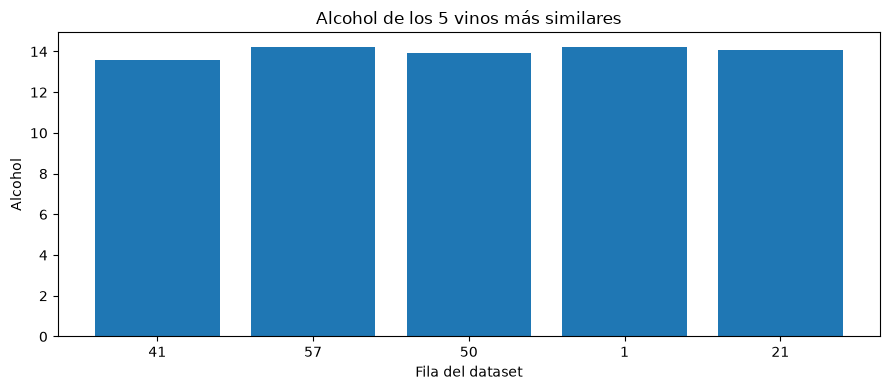

In [5]:
import matplotlib.pyplot as plt

plot_data = neighbors.sort_values("Distancia_estandarizada")
plt.figure(figsize=(9,4))
plt.bar(plot_data["Fila"].astype(str), plot_data["Alcohol"])
plt.xlabel("Fila del dataset")
plt.ylabel("Alcohol")
plt.title("Alcohol de los 5 vinos más similares")
plt.tight_layout()
plt.show()


# Problema 2. Market Basket

La práctica proporciona 11 tickets y solicita detectar patrones de consumo, además de hacer que el programa pueda trabajar con cualquier lista de compras que conserve el mismo formato: una lista de tickets, donde cada ticket es una lista de productos. filecite,turn0file0,L11-L22

Se implementa un Apriori general con tres parámetros:

- `min_support`: soporte mínimo.
- `min_confidence`: confianza mínima.
- `min_lift`: lift mínimo.

Para esta práctica se utiliza `min_support = 3/11 ≈ 0.273`, equivalente a que un patrón aparezca al menos en 3 tickets, y `min_confidence = 0.60`.

In [6]:
transactions = [
    ['bread', 'butter', 'wine', 'bananas', 'coffee', 'carrots'],
    ['tomatoes', 'onions', 'cheese', 'milk', 'potatoes'],
    ['beer', 'chips', 'asparagus', 'salsa', 'milk', 'apples'],
    ['olive oil', 'bread', 'butter', 'tomatoes', 'steak', 'carrots'],
    ['tomatoes', 'onions', 'chips', 'wine', 'ketchup', 'orange juice'],
    ['bread', 'butter', 'beer', 'chips', 'milk'],
    ['butter', 'tomatoes', 'carrots', 'coffee', 'sugar'],
    ['tomatoes', 'onions', 'cheese', 'milk', 'potatoes'],
    ['bread', 'butter', 'ketchup', 'coffee', 'chicken wings'],
    ['butter', 'beer', 'chips', 'asparagus', 'apples'],
    ['tomatoes', 'onion', 'beer', 'chips', 'milk', 'coffee']
]

print("Número de tickets:", len(transactions))
display(pd.DataFrame({"Ticket": range(1, len(transactions)+1),
                      "Productos": [", ".join(t) for t in transactions]}))

Número de tickets: 11


,Ticket,Productos
0,1,"bread, butter, wine, bananas, coffee, carrots"
1,2,"tomatoes, onions, cheese, milk, potatoes"
2,3,"beer, chips, asparagus, salsa, milk, apples"
3,4,"olive oil, bread, butter, tomatoes, steak, car..."
4,5,"tomatoes, onions, chips, wine, ketchup, orange..."
5,6,"bread, butter, beer, chips, milk"
6,7,"butter, tomatoes, carrots, coffee, sugar"
7,8,"tomatoes, onions, cheese, milk, potatoes"
8,9,"bread, butter, ketchup, coffee, chicken wings"
9,10,"butter, beer, chips, asparagus, apples"


In [7]:
from itertools import combinations

def market_basket_analysis(transactions, min_support=0.27,
                           min_confidence=0.60, min_lift=1.0):
    tx = [set(t) for t in transactions]
    n = len(tx)
    all_items = sorted(set().union(*tx))

    def support(itemset):
        s = set(itemset)
        return sum(s.issubset(t) for t in tx) / n

    frequent = {}
    for r in range(1, len(all_items) + 1):
        for comb in combinations(all_items, r):
            sup = support(comb)
            if sup >= min_support:
                frequent[comb] = sup

    frequent_df = pd.DataFrame([
        {"Itemset": ", ".join(k), "Soporte": v, "Tamaño": len(k)}
        for k, v in frequent.items()
    ]).sort_values(["Soporte", "Tamaño"], ascending=[False, False])

    rules = []
    for itemset, sup in frequent.items():
        if len(itemset) < 2:
            continue
        for r in range(1, len(itemset)):
            for ant in combinations(itemset, r):
                ant = tuple(sorted(ant))
                cons = tuple(sorted(set(itemset) - set(ant)))
                sup_ant = support(ant)
                sup_cons = support(cons)
                confidence = sup / sup_ant
                lift = confidence / sup_cons if sup_cons else np.nan

                if confidence >= min_confidence and lift >= min_lift:
                    rules.append({
                        "Antecedente": ", ".join(ant),
                        "Consecuente": ", ".join(cons),
                        "Soporte": sup,
                        "Confianza": confidence,
                        "Lift": lift
                    })

    rules_df = pd.DataFrame(rules)
    if not rules_df.empty:
        rules_df = rules_df.sort_values(
            ["Lift", "Confianza", "Soporte"], ascending=False
        )
    return frequent_df.reset_index(drop=True), rules_df.reset_index(drop=True)

frequent_itemsets, rules = market_basket_analysis(
    transactions,
    min_support=3/len(transactions),
    min_confidence=0.60,
    min_lift=1.0
)

display(frequent_itemsets.head(20))

,Itemset,Soporte,Tamaño
0,butter,0.545455,1
1,tomatoes,0.545455,1
2,chips,0.454545,1
3,milk,0.454545,1
4,"beer, chips",0.363636,2
5,"bread, butter",0.363636,2
6,beer,0.363636,1
7,bread,0.363636,1
8,coffee,0.363636,1
9,"beer, chips, milk",0.272727,3


# Reglas de asociación encontradas

Una regla `A → B` indica que cuando aparece `A`, también tiende a aparecer `B`. El **lift** permite evaluar si la asociación es mayor a la esperada por independencia:

- `Lift > 1`: asociación positiva.
- `Lift ≈ 1`: asociación débil o cercana a independencia.
- `Lift < 1`: asociación negativa.

In [8]:
display(rules.head(15).style.format({
    "Soporte": "{:.3f}",
    "Confianza": "{:.3f}",
    "Lift": "{:.3f}"
}))

,Antecedente,Consecuente,Soporte,Confianza,Lift
0,"chips, milk",beer,0.273,1.000,2.750
1,beer,"chips, milk",0.273,0.750,2.750
2,beer,chips,0.364,1.000,2.200
3,"beer, milk",chips,0.273,1.000,2.200
4,chips,beer,0.364,0.800,2.200
5,chips,"beer, milk",0.273,0.600,2.200
6,bread,butter,0.364,1.000,1.833
7,carrots,butter,0.273,1.000,1.833
8,onions,tomatoes,0.273,1.000,1.833
9,butter,bread,0.364,0.667,1.833


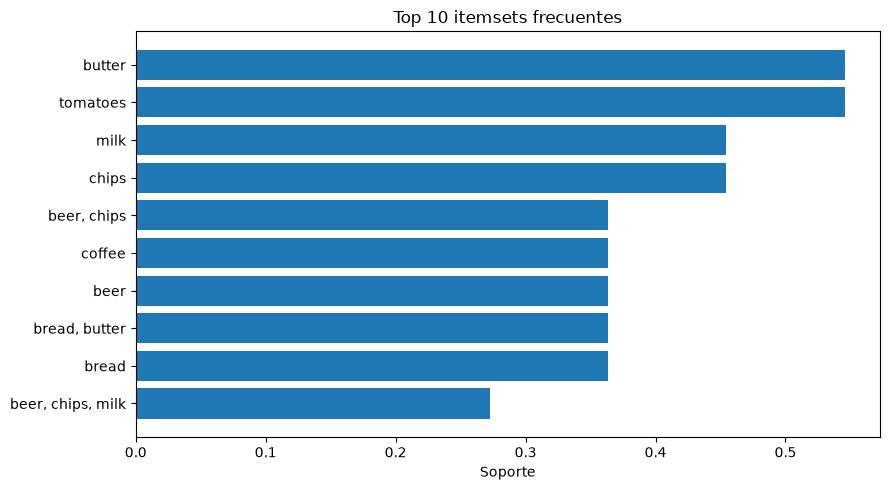

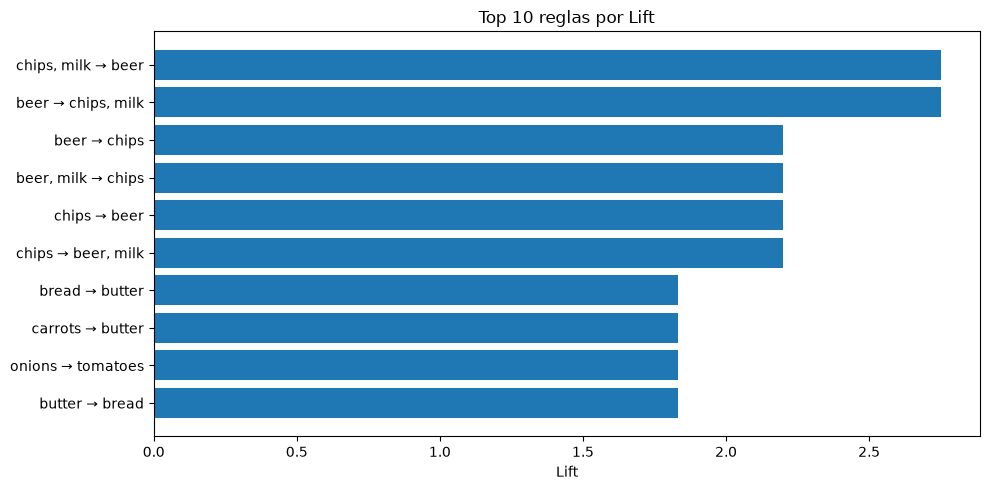

In [9]:
top = frequent_itemsets.head(10).sort_values("Soporte")
plt.figure(figsize=(9,5))
plt.barh(top["Itemset"], top["Soporte"])
plt.xlabel("Soporte")
plt.title("Top 10 itemsets frecuentes")
plt.tight_layout()
plt.show()

top_rules = rules.head(10).copy()
labels = (top_rules["Antecedente"] + " → " + top_rules["Consecuente"]).tolist()[::-1]
values = top_rules["Lift"].tolist()[::-1]
plt.figure(figsize=(10,5))
plt.barh(labels, values)
plt.xlabel("Lift")
plt.title("Top 10 reglas por Lift")
plt.tight_layout()
plt.show()

# Conclusiones

### Problema 1
El algoritmo KNN, aplicado sobre las variables estandarizadas, identifica cinco vinos químicamente más cercanos a la muestra objetivo. Las concentraciones de alcohol de esos vecinos son **13.56, 14.22, 13.94, 14.23 y 14.06**, cuyo promedio es **14.002**.

### Problema 2
Los patrones más consistentes se concentran alrededor de `beer`, `chips`, `milk`, `bread`, `butter` y `tomatoes`. En particular, la combinación `beer + chips + milk` aparece en 3 de los 11 tickets, y las reglas asociadas presentan lifts superiores a 1.

La interpretación debe hacerse con cautela porque solamente hay 11 tickets. Por ello se fijó un soporte mínimo de 3 tickets para evitar que asociaciones presentes una sola vez aparezcan como patrones fuertes.

### Reutilización
La función `market_basket_analysis()` recibe cualquier lista con el mismo formato y permite cambiar soporte, confianza y lift. Así, el código puede reutilizarse con otras listas de compras sin modificar el algoritmo.
